In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data = pd.read_csv('heart.csv')

In [6]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [7]:
data.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [8]:
data.shape

(1025, 14)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [10]:
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [11]:
data_dup = data.duplicated().sum()
print(data_dup)

723


In [12]:
data = data.drop_duplicates()

In [13]:
data.shape

(302, 14)

In [14]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [15]:
#correlation of dataset
data.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.094962,-0.063107,0.283121,0.207216,0.119492,-0.111590,-0.395235,0.093216,0.206040,-0.164124,0.302261,0.065317,-0.221476
sex,-0.094962,1.000000,-0.051740,-0.057647,-0.195571,0.046022,-0.060351,-0.046439,0.143460,0.098322,-0.032990,0.113060,0.211452,-0.283609
cp,-0.063107,-0.051740,1.000000,0.046486,-0.072682,0.096018,0.041561,0.293367,-0.392937,-0.146692,0.116854,-0.195356,-0.160370,0.432080
trestbps,0.283121,-0.057647,0.046486,1.000000,0.125256,0.178125,-0.115367,-0.048023,0.068526,0.194600,-0.122873,0.099248,0.062870,-0.146269
chol,0.207216,-0.195571,-0.072682,0.125256,1.000000,0.011428,-0.147602,-0.005308,0.064099,0.050086,0.000417,0.086878,0.096810,-0.081437
fbs,0.119492,0.046022,0.096018,0.178125,0.011428,1.000000,-0.083081,-0.007169,0.024729,0.004514,-0.058654,0.144935,-0.032752,-0.026826
restecg,-0.111590,-0.060351,0.041561,-0.115367,-0.147602,-0.083081,1.000000,0.041210,-0.068807,-0.056251,0.090402,-0.083112,-0.010473,0.134874
thalach,-0.395235,-0.046439,0.293367,-0.048023,-0.005308,-0.007169,0.041210,1.000000,-0.377411,-0.342201,0.384754,-0.228311,-0.094910,0.419955
exang,0.093216,0.143460,-0.392937,0.068526,0.064099,0.024729,-0.068807,-0.377411,1.000000,0.286766,-0.256106,0.125377,0.205826,-0.435601
oldpeak,0.206040,0.098322,-0.146692,0.194600,0.050086,0.004514,-0.056251,-0.342201,0.286766,1.000000,-0.576314,0.236560,0.209090,-0.429146


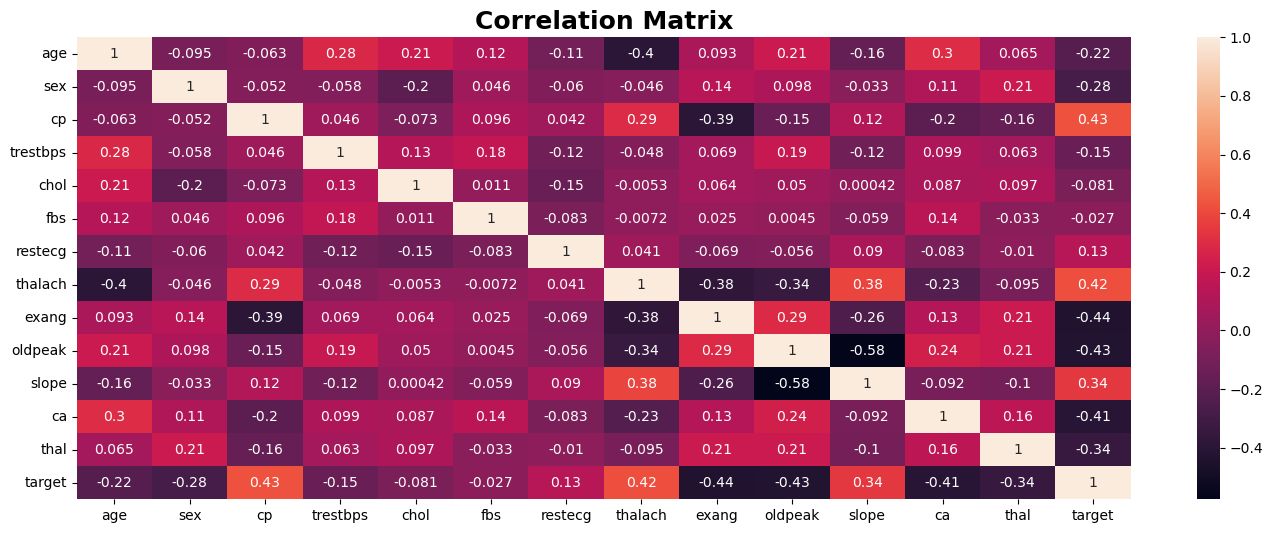

In [16]:
plt.figure(figsize=(17,6))
plt.title("Correlation Matrix",size=18,fontweight='bold')
sns.heatmap(data.corr(),annot=True)
plt.show()

In [17]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [18]:
data['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

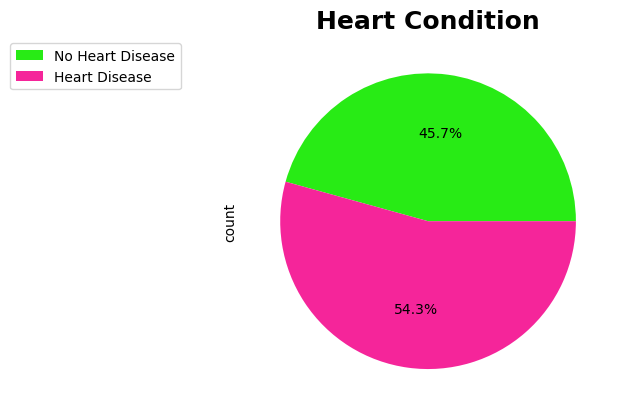

In [19]:
counts = data['target'].value_counts().sort_index()
counts.plot(kind='pie',labels=None, autopct='%1.1f%%',colors=['#28EB15', '#F5259A'])
plt.legend(['No Heart Disease', 'Heart Disease'],bbox_to_anchor=(-0.15, 1))
plt.title("Heart Condition",size=18,fontweight='bold')
plt.show()

In [20]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [21]:
data['sex'].value_counts()

sex
1    206
0     96
Name: count, dtype: int64

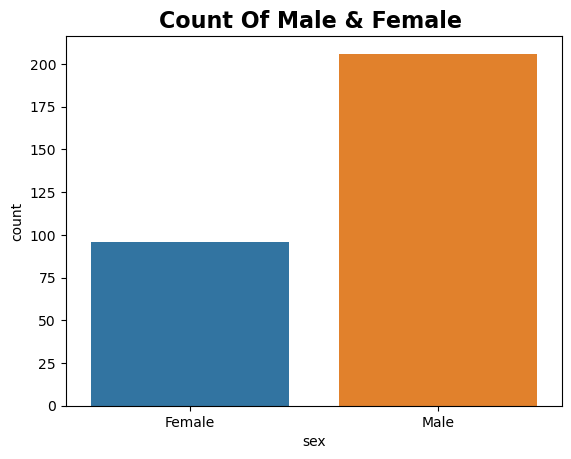

In [22]:
sns.countplot(x='sex', data=data, hue='sex', legend=False)
plt.xticks([0,1],['Female','Male'])
plt.title("Count Of Male & Female ",size=16,fontweight='bold')
plt.show()

In [23]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [24]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

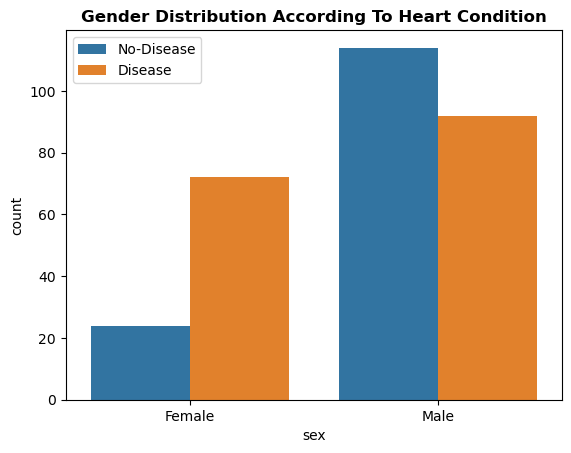

In [25]:
sns.countplot(x='sex', hue="target", data=data)
plt.xticks([1, 0],['Male','Female'])
plt.legend(labels=['No-Disease', 'Disease'])
plt.title("Gender Distribution According To Heart Condition",size=12,fontweight='bold')
plt.show ()

In [26]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

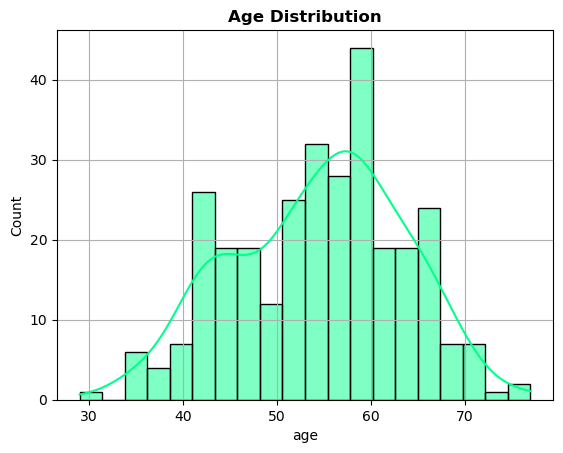

In [27]:
sns.histplot(data['age'], bins=20, kde=True, color="#00FF8B")
plt.title("Age Distribution",size=12,fontweight='bold')
plt.grid()
plt.show()

In [28]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

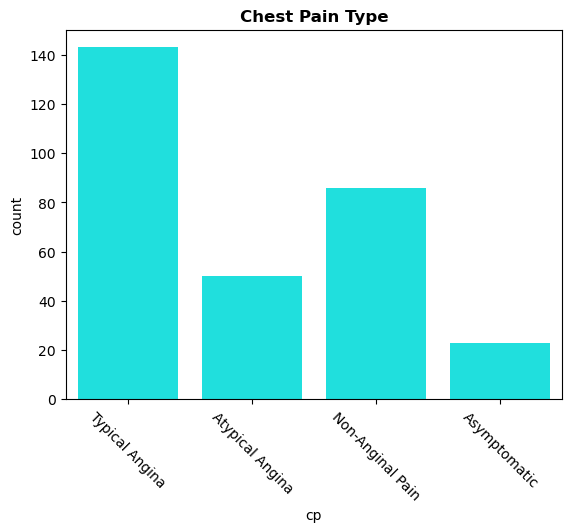

In [29]:
sns.countplot(x='cp', data=data, color = "#00FFFC")
plt.xticks([0,1,2,3],['Typical Angina','Atypical Angina','Non-Anginal Pain','Asymptomatic'])
plt.xticks(rotation=-45)
plt.title("Chest Pain Type",size=12,fontweight='bold')
plt.show()

In [30]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

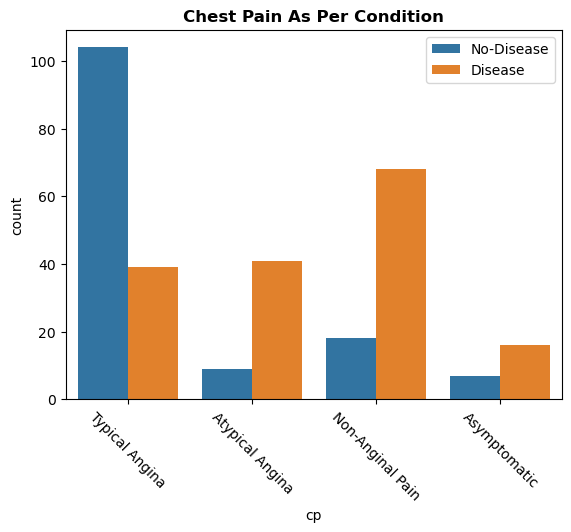

In [31]:
sns.countplot(x='cp', hue='target',data=data)
plt.legend(labels=['No-Disease', 'Disease'])
plt.xticks([0,1,2,3],['Typical Angina','Atypical Angina','Non-Anginal Pain','Asymptomatic'])
plt.xticks(rotation=-45)
plt.title("Chest Pain As Per Condition",size=12,fontweight='bold')
plt.show()

In [32]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

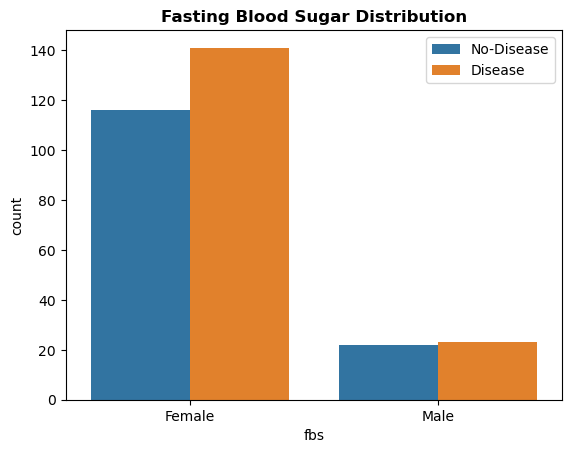

In [34]:
sns.countplot(x='fbs', hue='target',data=data)
plt.legend(labels=['No-Disease', 'Disease'])
plt.xticks([1, 0],['Male','Female'])
plt.title("Fasting Blood Sugar Distribution",size=12,fontweight='bold')
plt.show()

In [35]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

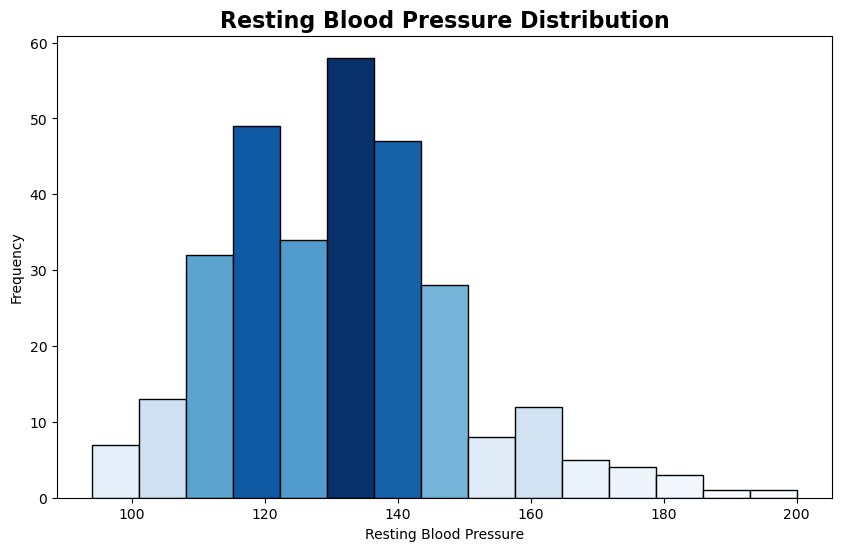

In [41]:
counts, bins = np.histogram(data['trestbps'], bins=15)
norm = plt.Normalize(counts.min(), counts.max())
colors = plt.cm.Blues(norm(counts))
plt.figure(figsize=(10,6))

for i in range(len(counts)):
    plt.bar(bins[i], counts[i], width=bins[i+1]-bins[i], align='edge', color=colors[i], edgecolor='black')

plt.title("Resting Blood Pressure Distribution", fontsize=16, fontweight='bold')
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Frequency")

plt.show()

In [42]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

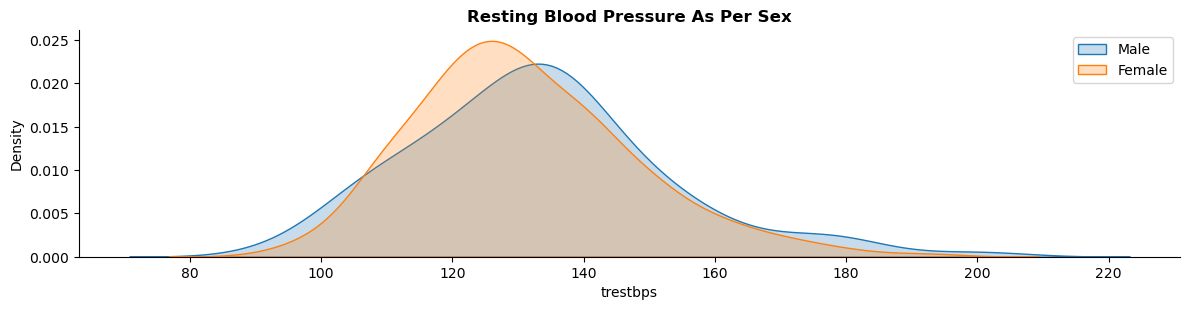

In [46]:
g = sns.FacetGrid(data, hue="sex", aspect=4)

g.map(sns.kdeplot, 'trestbps', fill=True)

plt.legend(labels=['Male', 'Female'])
plt.title("Resting Blood Pressure As Per Sex", fontsize=12, fontweight='bold')
plt.show()

In [47]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

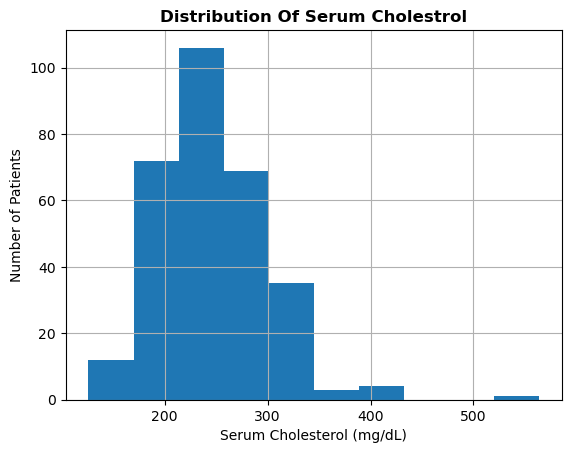

In [49]:
data['chol'].hist()
plt.title("Distribution Of Serum Cholestrol", fontsize=12, fontweight='bold')
plt.xlabel("Serum Cholesterol (mg/dL)", fontsize=10)
plt.ylabel("Number of Patients", fontsize=10)

plt.show()

In [50]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [52]:
cate_val = []
cont_val = []

for column in data.columns:
    if data[column].nunique() < 10:
        cate_val.append(column)
    else:
        cont_val.append(column)

In [53]:
cate_val  #category value

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [57]:
cont_val #continous value

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

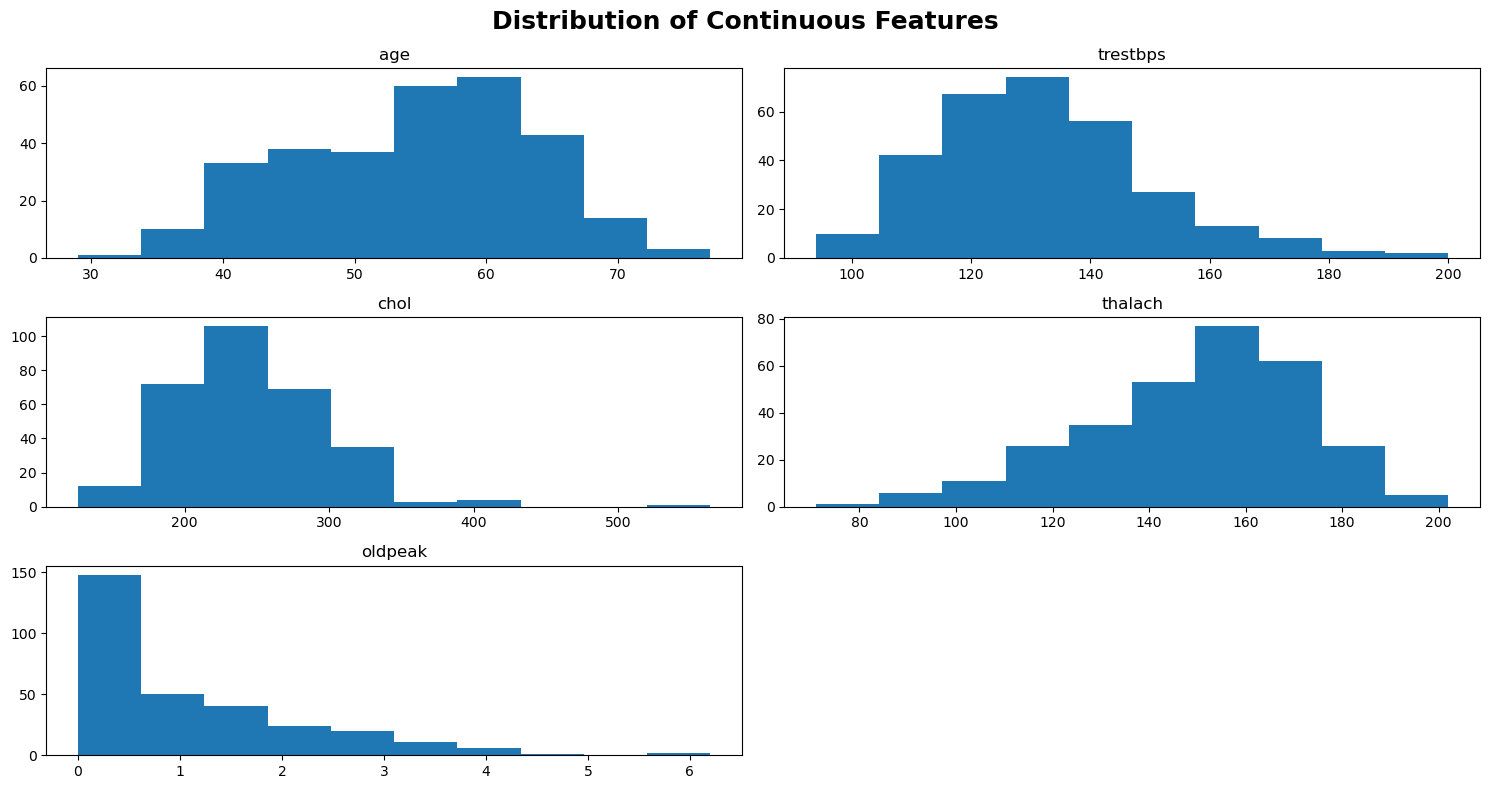

In [70]:
data.hist (cont_val, figsize=(15,8), grid=False)
plt.suptitle("Distribution of Continuous L",fontsize=18,fontweight='bold')
plt.tight_layout ()
plt.show()

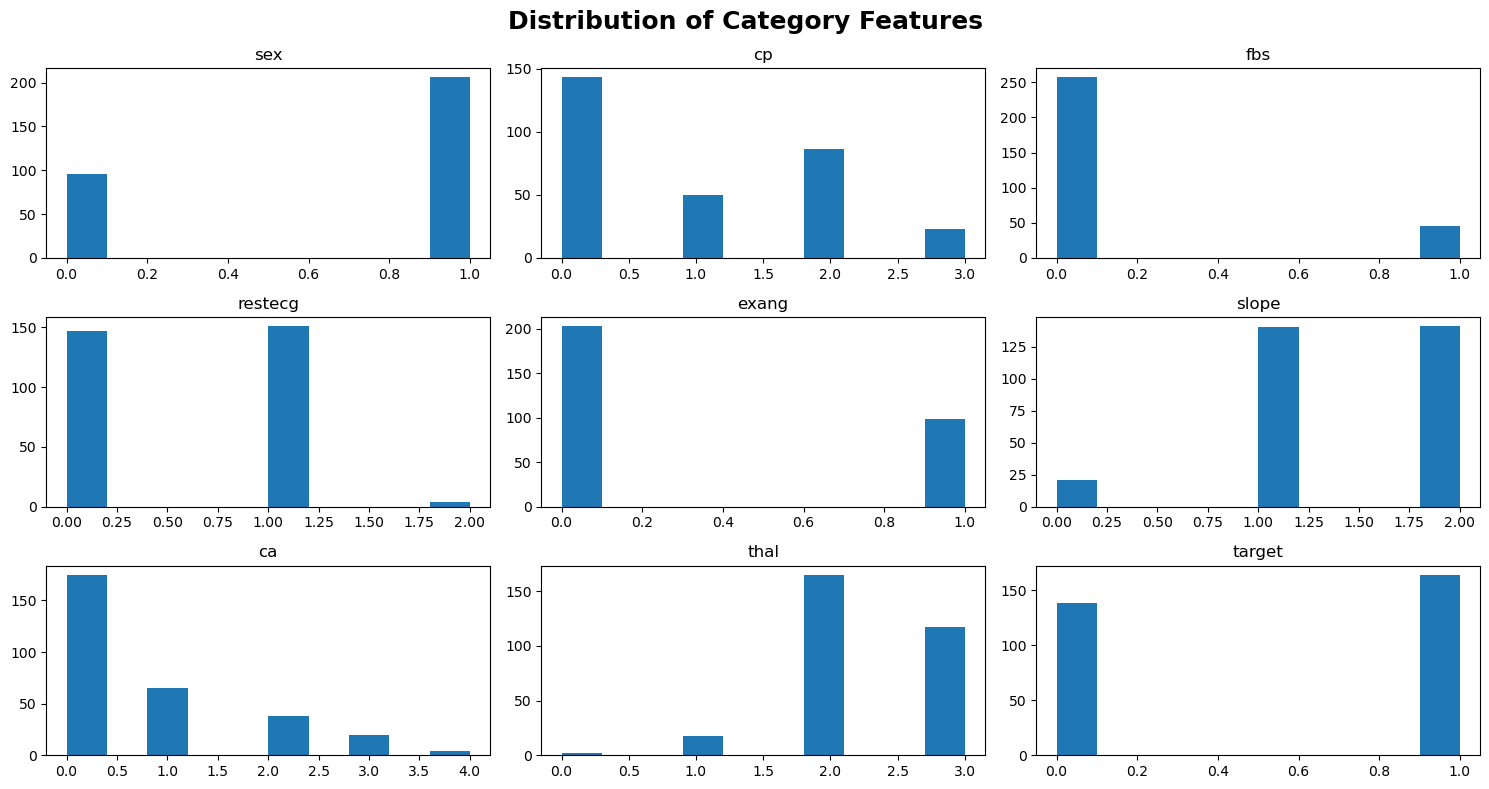

In [71]:
data.hist (cate_val, figsize=(15,8), grid=False)
plt.suptitle("Distribution of Category Features",fontsize=18,fontweight='bold')
plt.tight_layout ()
plt.show()